# Population and built-up surface exposed to river flooding

We use the JRC flood maps, JRC GHSL population and built-surface layers and Geoboundaries ADM0 country boundary to calculate exposure, with two main results:

- **Depth bands**, which do not overlap: `(0, 0.1]`, `(0.1, 0.5]`, `(0.5, 1]`, `(1, 2]`, `(2, 5]` and `> 5` metres.
- **Thresholds**, which overlap: exposure to depth greater than 0, 0.1, 0.5, 1, 2 and 5 metres.

A 100-year return period means a 1% annual probability of an event of that magnitude being equalled or exceeded under the model's assumptions. It does not mean floods arrive exactly 100 years apart. Each return period is a separate scenario; do not add their exposed populations together.

The year 2025 describes the exposure layers, not a forecast of flood conditions in 2025. These are estimates of spatial exposure, not numbers of casualties, damaged buildings or annual losses.

## Find the files with pathlib

`Path` represents a location on disk. The `/` operator joins path components, and `glob` finds filenames matching a pattern. This cell finds `incoming_data` whether Jupyter starts in `tha-demos` or the repository root. If your files are elsewhere, set `DATA_DIR` directly.

We choose **GHS_BUILT_S**, the total built-up surface layer. **GHS_BUILT_S_NRES** describes the non-residential subset and might be interesting to explore separately, but we don't use it here.

In [1]:
from pathlib import Path

possible_roots = [Path.cwd(), Path.cwd() / "tha-demos", *Path.cwd().parents]
DEMO_DIR = next(
    (p for p in possible_roots if (p / "incoming_data/starter-data-kit/data/THA").is_dir()),
    None,
)
if DEMO_DIR is None:
    raise FileNotFoundError("Set DATA_DIR to your starter-data-kit/data/THA directory.")
DATA_DIR = DEMO_DIR / "incoming_data/starter-data-kit/data/THA"
GHSL_DIR = DATA_DIR / "jrc_ghsl"
FLOOD_DIR = DATA_DIR / "jrc_floods"
BOUNDARY_PATH = DATA_DIR / "geoboundaries/geoBoundaries-THA-ADM0.gpkg"

POP_PATH = GHSL_DIR / "GHS_POP_E2025_GLOBE_R2023A_4326_30ss_V1_0__THA.tif"
BUILT_PATH = GHSL_DIR / "GHS_BUILT_S_E2025_GLOBE_R2023A_4326_30ss_V1_0__THA.tif"
flood_paths = {}
for path in FLOOD_DIR.glob("floodMapGL_rp*y__THA.tif"):
    years = int(path.name.split("_rp")[1].split("y")[0])
    flood_paths[years] = path
flood_paths = dict(sorted(flood_paths.items()))
for path in [POP_PATH, BUILT_PATH, BOUNDARY_PATH]:
    if not path.is_file():
        raise FileNotFoundError(path)
if not flood_paths:
    raise FileNotFoundError(f"No flood maps found in {FLOOD_DIR}")
print("Data directory:", DATA_DIR)
print("Return periods (years):", list(flood_paths))

Data directory: /home/mert2014/projects/snail-datapkg-demos/tha-demos/incoming_data/starter-data-kit/data/THA
Return periods (years): [10, 20, 50, 100, 200, 500]


## Open a GeoTIFF with Rasterio

A **raster** is a rectangular grid of cells. A **GeoTIFF** stores both the cell values and their geographic location. A **band** is one grid of values; these files have one band.

The **coordinate reference system (CRS)** tells us how coordinates relate to the Earth. EPSG:4326 uses longitude and latitude in degrees. The **transform** gives the grid origin, cell size and orientation. **NoData** is a marker for missing or unreported values.

The `with` statement closes a file automatically when we finish reading it. `read(1, masked=True)` reads band 1 and marks NoData cells as missing.

In [2]:
import pandas
import rasterio

example_rp = 100 if 100 in flood_paths else next(iter(flood_paths))
input_paths = {"population_2025": POP_PATH, "built_up_2025": BUILT_PATH}
input_paths.update({f"flood_rp{rp}": path for rp, path in flood_paths.items()})
metadata_rows = []
for name, path in input_paths.items():
    with rasterio.open(path) as src:
        metadata_rows.append({
            "layer": name, "crs": str(src.crs), "rows": src.height,
            "columns": src.width, "bands": src.count,
            "left": src.transform.c, "top": src.transform.f,
            "cell_width_degrees": src.transform.a,
            "cell_height_degrees": -src.transform.e,
            "nodata": src.nodata,
        })
        if src.count != 1 or src.crs is None:
            raise ValueError(f"Expected one georeferenced band: {path}")
        if src.scales != (1.0,) or src.offsets != (0.0,):
            raise ValueError(f"Apply the scale/offset before using this tutorial: {path}")

metadata_df = pandas.DataFrame(metadata_rows)
display(metadata_df)

with rasterio.open(POP_PATH) as src:
    population = src.read(1, masked=True)
    pop_grid = {"crs": src.crs, "transform": src.transform, "shape": src.shape}
with rasterio.open(BUILT_PATH) as src:
    built_up = src.read(1, masked=True)
    built_grid = {"crs": src.crs, "transform": src.transform, "shape": src.shape}
with rasterio.open(flood_paths[example_rp]) as src:
    example_depth_native = src.read(1, masked=True)
    flood_grid = {"crs": src.crs, "transform": src.transform, "shape": src.shape}

,layer,crs,rows,columns,bands,left,top,cell_width_degrees,cell_height_degrees,nodata
0,population_2025,EPSG:4326,1780,998,1,97.342083,20.457917,0.008333,0.008333,NaN
1,built_up_2025,EPSG:4326,1780,998,1,97.340416,20.457917,0.008333,0.008333,NaN
2,flood_rp10,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38
3,flood_rp20,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38
4,flood_rp50,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38
5,flood_rp100,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38
6,flood_rp200,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38
7,flood_rp500,EPSG:4326,1780,998,1,97.341679,20.458431,0.008333,0.008333,-3.402823e+38


**Units matter.** GHSL population values are people per cell, and built-up values are square metres per cell. Sum the values directly; multiplying them by cell area would give incorrect units. Fractional population values reflect a model distributing people among cells. Keep those fractions during calculation.

These local files have approximately 30 arc-second cells (about 1 km, depending on latitude). Their dimensions match, but their origins differ slightly. Just because the arrays have equal numbers of rows and columns, it does not mean that they are perfectly aligned geographically. We will address that before combining flood depths and exposure values.

## Understand arrays and masks with NumPy

**NumPy** works with grids of numbers. An array has a `shape` (rows, columns). A **Boolean mask** is a grid of `True` and `False` values that selects cells. `isfinite` rejects NaN and infinity. `&` combines conditions, and `~` reverses a Boolean mask. Parentheses keep the comparisons separate.

We distinguish a valid zero from a missing value. Negative population or built-up values are not valid counts. Flood NoData cells are kept missing; we do not replace them with zero.

In [3]:
import numpy as np

pop_values = population.filled(np.nan)
built_values = built_up.filled(np.nan)
pop_valid = (~np.ma.getmaskarray(population)) & np.isfinite(pop_values) & (pop_values >= 0)
built_valid = (~np.ma.getmaskarray(built_up)) & np.isfinite(built_values) & (built_values >= 0)
native_depth = example_depth_native.filled(np.nan)
print("Population array shape:", pop_values.shape)
print("Example flood cells with a recorded depth:", np.count_nonzero(np.isfinite(native_depth)))
print("Example flood cells without a recorded depth:", np.count_nonzero(~np.isfinite(native_depth)))
print("Recorded depth range (m):", np.nanmin(native_depth), np.nanmax(native_depth))

Population array shape: (1780, 998)
Example flood cells with a recorded depth: 140583
Example flood cells without a recorded depth: 1635857
Recorded depth range (m): 0.01 30.0


## Read the ADM0 country boundary with GeoPandas

The raster grids also overlap with neighbouring countries. **GeoPandas** reads geographic features, such as the polygon which is Thailand's country boundary, into a table with a geometry column. In the starter data kit, boundaries are stored in GeoPackage (`.gpkg`) files containing those features and their CRS.

Rasterio's `geometry_mask` turns the polygon into a Boolean (true/false) grid. We include a raster cell when its centre lies inside Thailand, using `all_touched=False`. Border cells are included in full or excluded in full; we do not estimate fractions of population or built-up surface in cells crossing the border.

In [4]:
import geopandas as gpd
from rasterio.features import geometry_mask

country = gpd.read_file(BOUNDARY_PATH)
if country.empty or country.crs is None or country.geometry.isna().any():
    raise ValueError("ADM0 must contain geometries with a known CRS.")
if not country.geometry.is_valid.all():
    raise ValueError("Repair invalid ADM0 geometries before continuing.")

def country_mask(grid):
    """True for cells whose centres are inside the ADM0 outline."""
    boundary = country.to_crs(grid["crs"])
    return geometry_mask(
        boundary.geometry, out_shape=grid["shape"],
        transform=grid["transform"], invert=True, all_touched=False,
    )

pop_inside = country_mask(pop_grid)
built_inside = country_mask(built_grid)
pop_eligible = pop_inside & pop_valid
built_eligible = built_inside & built_valid
pop_total = pop_values[pop_eligible].sum(dtype="float64")
built_total = built_values[built_eligible].sum(dtype="float64")
print(f"2025 population in eligible Thailand cells: {pop_total:,.1f} people")
print(f"2025 built-up surface in eligible Thailand cells: {built_total:,.1f} m²")
print("Thailand cells missing valid population:", np.count_nonzero(pop_inside & ~pop_valid))
print("Thailand cells missing valid built-up surface:", np.count_nonzero(built_inside & ~built_valid))

2025 population in eligible Thailand cells: 71,900,417.7 people
2025 built-up surface in eligible Thailand cells: 7,183,920,248.0 m²
Thailand cells missing valid population: 0
Thailand cells missing valid built-up surface: 0


## Map the built-up surface and population data with Matplotlib

**Matplotlib** draws figures. A figure holds one or more **axes** (individual panels). `imshow` displays a grid, and a colour bar explains the values. `plotting_extent` places the grid at its true coordinates; GeoPandas can draw the ADM0 outline on the same axes.

We mask values outside Thailand for each panel. Each colour range is capped at its {PLOT_PERCENTILE}th percentile to make smaller values visible; cells above that limit share the darkest or brightest colour. This only changes the display. Longitude/latitude maps provide geographic context but do not preserve ground area.

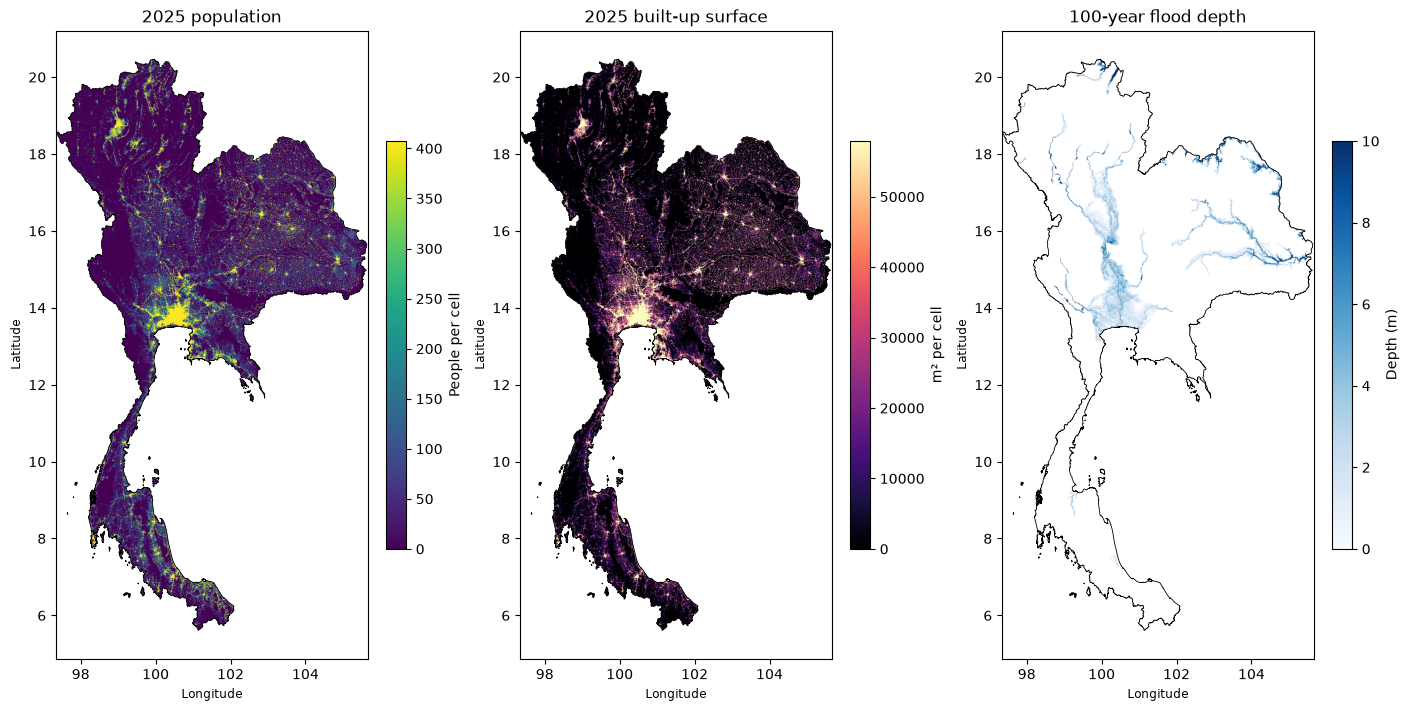

In [5]:
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

PLOT_PERCENTILE = 95

flood_inside = country_mask(flood_grid)
fig, axes = plt.subplots(1, 3, figsize=(14, 7), constrained_layout=True)
panels = [
    (pop_values, pop_eligible, pop_grid, "2025 population", "People per cell", "viridis",
     np.percentile(pop_values[pop_eligible], PLOT_PERCENTILE)),
    (built_values, built_eligible, built_grid, "2025 built-up surface", "m² per cell", "magma",
     np.percentile(built_values[built_eligible], PLOT_PERCENTILE)),
    (native_depth, flood_inside & np.isfinite(native_depth), flood_grid,
     f"{example_rp}-year flood depth", "Depth (m)", "Blues",
     np.percentile(native_depth[flood_inside & np.isfinite(native_depth)], PLOT_PERCENTILE)),
]
for ax, (values, valid, grid, title, units, cmap, vmax) in zip(axes, panels):
    image = ax.imshow(
        np.ma.array(values, mask=~valid),
        extent=plotting_extent(values, grid["transform"]),
        origin="upper", cmap=cmap, vmin=0, vmax=vmax,
    )
    country.to_crs(grid["crs"]).boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set(title=title, xlabel="Longitude", ylabel="Latitude")
    fig.colorbar(image, ax=ax, shrink=0.65, label=units)
plt.show()

## Align flood depths to each exposure grid

To compare cells, they must share a CRS, transform and dimensions. Rasterio's `reproject` can align rasters even when their CRS is already the same. We move the **hazard** onto each original exposure grid, keeping all population counts and built-up quantities unchanged. Each exposure cell receives the depth of the nearest hazard cell at its centre.

We use **nearest-neighbour resampling** to preserve recorded depth values and missing cells without inventing intermediate depths. This is a screening approximation: a single depth is assigned to the whole exposure cell. It does not estimate the flooded fraction of that cell or the locations of people and buildings within it. The supplied TIFFs have already been processed into coarse grids; this notebook cannot recover detail or correct upstream resampling choices.

The helper function below packages repeated instructions. Its input is a path and a target grid; its output is a depth array. Missing and negative depth values become NaN.

In [6]:
from rasterio.warp import reproject, Resampling

def depth_on_grid(path, grid):
    """Assign nearest flood depths to an original exposure grid."""
    with rasterio.open(path) as src:
        source = src.read(1, masked=True).astype("float32").filled(np.nan)
        source[~np.isfinite(source) | (source < 0)] = np.nan
        destination = np.full(grid["shape"], np.nan, dtype="float32")
        reproject(
            source=source, destination=destination,
            src_transform=src.transform, src_crs=src.crs, src_nodata=np.nan,
            dst_transform=grid["transform"], dst_crs=grid["crs"], dst_nodata=np.nan,
            resampling=Resampling.nearest,
        )
    return destination

example_pop_depth = depth_on_grid(flood_paths[example_rp], pop_grid)
example_built_depth = depth_on_grid(flood_paths[example_rp], built_grid)
print("Depth on population grid:", example_pop_depth.shape)
print("Depth on built-up grid:", example_built_depth.shape)

Depth on population grid: (1780, 998)
Depth on built-up grid: (1780, 998)


## Select exposed cells and sum their values

For a threshold of 0.5 m, select Thailand cells with valid exposure, a recorded flood depth and `depth > 0.5`. Indexing an array with this mask extracts the selected values. Adding them gives the exposure estimate.

**NoData interpretation:** the supplied flood maps have recorded positive depths and many NoData cells. NoData does not distinguish dry land, locations outside the modelled river network and missing coverage. Our exposure estimates therefore count only cells with recorded depths.

In [7]:
threshold_m = 0.5
pop_selected = pop_eligible & np.isfinite(example_pop_depth) & (example_pop_depth > threshold_m)
built_selected = built_eligible & np.isfinite(example_built_depth) & (example_built_depth > threshold_m)
example_people = pop_values[pop_selected].sum(dtype="float64") / 1e6 # divide by 1,000,000 to get million people from people
example_surface = built_values[built_selected].sum(dtype="float64") / 1e6 # divide by 1,000,000 to get square kilometres from square metres
print(f"{example_rp}-year scenario, depth > {threshold_m} m:")
print(f"    Population: {example_people:,.1f} million people")
print(f"    Built-up surface: {example_surface:,.0f} km²")

100-year scenario, depth > 0.5 m:
    Population: 25.0 million people
    Built-up surface: 1,719 km²


## Build tables with pandas

**pandas** organises records into a **DataFrame**, a table with named columns. We first collect dictionaries (one record per band or threshold), then turn the list of records into a table.

The band rule is **lower < depth ≤ upper**. Thus a depth of exactly 0.5 m belongs to `(0.1, 0.5]`, and does not pass the `> 0.5 m` threshold.

All six return periods use the same 2025 exposure layers. Population and built-up totals can use slightly different cell selections because their original grids differ. Percentages use the national totals computed above as denominators.

In [8]:
import pandas as pd

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
depth_breaks_m = [0, 0.1, 0.5, 1, 2, 5]
band_edges_m = depth_breaks_m + [np.inf]
band_labels = []
for lower, upper in zip(band_edges_m[:-1], band_edges_m[1:]):
    label = f"({lower:g}, {upper:g}] m" if np.isfinite(upper) else f"> {lower:g} m"
    band_labels.append(label)
metadata = pd.DataFrame(metadata_rows)
display(metadata)

def exposure_record(rp, pop_selection, built_selection):
    people = pop_values[pop_selection].sum(dtype="float64")
    surface = built_values[built_selection].sum(dtype="float64")
    return {
        "return_period_years": rp,
        "annual_exceedance_probability_pct": 100 / rp,
        "population_people": people,
        "built_up_m2": surface,
        "population_pct_of_national_total": 100 * people / pop_total if pop_total else np.nan,
        "built_up_pct_of_national_total": 100 * surface / built_total if built_total else np.nan,
    }

,layer,crs,rows,columns,bands,left,top,cell_width_degrees,cell_height_degrees,nodata
0,population_2025,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,NaN
1,built_up_2025,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,NaN
2,flood_rp10,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."
3,flood_rp20,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."
4,flood_rp50,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."
5,flood_rp100,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."
6,flood_rp200,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."
7,flood_rp500,EPSG:4326,1780,998,1,97.34,20.46,0.01,0.01,"-340,282,306,073,709,652,508,363,335,590,014,35..."


In [9]:
band_rows = []
threshold_rows = []
coverage_rows = []
for rp, path in flood_paths.items():
    pop_depth = depth_on_grid(path, pop_grid)
    built_depth = depth_on_grid(path, built_grid)
    pop_recorded = pop_eligible & np.isfinite(pop_depth)
    built_recorded = built_eligible & np.isfinite(built_depth)

    for lower, upper, label in zip(band_edges_m[:-1], band_edges_m[1:], band_labels):
        row = exposure_record(
            rp, pop_recorded & (pop_depth > lower) & (pop_depth <= upper),
            built_recorded & (built_depth > lower) & (built_depth <= upper),
        )
        row.update({"depth_band": label, "lower_depth_m_exclusive": lower,
                    "upper_depth_m_inclusive": upper})
        band_rows.append(row)

    for threshold in depth_breaks_m:
        row = exposure_record(
            rp, pop_recorded & (pop_depth > threshold),
            built_recorded & (built_depth > threshold),
        )
        row["depth_threshold_m_exclusive"] = threshold
        threshold_rows.append(row)

    # Partition each eligible national total into recorded-positive,
    # recorded-zero and no-recorded-depth cells.
    for status in ["recorded_positive_depth", "recorded_zero_depth", "no_recorded_depth"]:
        if status == "recorded_positive_depth":
            p = pop_recorded & (pop_depth > 0)
            b = built_recorded & (built_depth > 0)
        elif status == "recorded_zero_depth":
            p = pop_recorded & (pop_depth == 0)
            b = built_recorded & (built_depth == 0)
        else:
            p = pop_eligible & ~np.isfinite(pop_depth)
            b = built_eligible & ~np.isfinite(built_depth)
        row = exposure_record(rp, p, b)
        row.update({"hazard_status": status, "population_grid_cells": int(p.sum()),
                    "built_up_grid_cells": int(b.sum())})
        coverage_rows.append(row)
    print(f"Completed {rp}-year scenario")

bands = pd.DataFrame(band_rows)
thresholds = pd.DataFrame(threshold_rows)
coverage = pd.DataFrame(coverage_rows)
display(bands)
display(thresholds)
display(coverage)

Completed 10-year scenario
Completed 20-year scenario
Completed 50-year scenario
Completed 100-year scenario
Completed 200-year scenario
Completed 500-year scenario


,return_period_years,annual_exceedance_probability_pct,population_people,built_up_m2,population_pct_of_national_total,built_up_pct_of_national_total,depth_band,lower_depth_m_exclusive,upper_depth_m_inclusive
0,10,10.00,"1,473,655.87","115,125,127.00",2.05,1.60,"(0, 0.1] m",0.00,0.10
1,10,10.00,"4,012,720.62","289,466,747.00",5.58,4.03,"(0.1, 0.5] m",0.10,0.50
2,10,10.00,"5,063,843.41","310,367,199.00",7.04,4.32,"(0.5, 1] m",0.50,1.00
3,10,10.00,"9,069,835.85","532,282,029.00",12.61,7.41,"(1, 2] m",1.00,2.00
4,10,10.00,"5,821,576.79","455,137,190.00",8.10,6.34,"(2, 5] m",2.00,5.00
5,10,10.00,"1,650,408.52","156,478,370.00",2.30,2.18,> 5 m,5.00,inf
6,20,5.00,"1,348,317.79","103,024,559.00",1.88,1.43,"(0, 0.1] m",0.00,0.10
7,20,5.00,"3,662,654.52","276,759,484.00",5.09,3.85,"(0.1, 0.5] m",0.10,0.50
8,20,5.00,"4,559,241.29","301,168,582.00",6.34,4.19,"(0.5, 1] m",0.50,1.00
9,20,5.00,"9,706,321.31","564,688,735.00",13.50,7.86,"(1, 2] m",1.00,2.00


,return_period_years,annual_exceedance_probability_pct,population_people,built_up_m2,population_pct_of_national_total,built_up_pct_of_national_total,depth_threshold_m_exclusive
0,10,10.00,"27,092,041.06","1,858,856,662.00",37.68,25.88,0.00
1,10,10.00,"25,618,385.18","1,743,731,535.00",35.63,24.27,0.10
2,10,10.00,"21,605,664.56","1,454,264,788.00",30.05,20.24,0.50
3,10,10.00,"16,541,821.15","1,143,897,589.00",23.01,15.92,1.00
4,10,10.00,"7,471,985.31","611,615,560.00",10.39,8.51,2.00
5,10,10.00,"1,650,408.52","156,478,370.00",2.30,2.18,5.00
6,20,5.00,"27,935,202.63","1,929,952,648.00",38.85,26.86,0.00
7,20,5.00,"26,586,884.84","1,826,928,089.00",36.98,25.43,0.10
8,20,5.00,"22,924,230.32","1,550,168,605.00",31.88,21.58,0.50
9,20,5.00,"18,364,989.04","1,249,000,023.00",25.54,17.39,1.00


,return_period_years,annual_exceedance_probability_pct,population_people,built_up_m2,population_pct_of_national_total,built_up_pct_of_national_total,hazard_status,population_grid_cells,built_up_grid_cells
0,10,10.00,"27,092,041.06","1,858,856,662.00",37.68,25.88,recorded_positive_depth,64416,64457
1,10,10.00,0.00,0.00,0.00,0.00,recorded_zero_depth,0,0
2,10,10.00,"44,808,376.67","5,325,063,586.00",62.32,74.12,no_recorded_depth,560025,559998
3,20,5.00,"27,935,202.63","1,929,952,648.00",38.85,26.86,recorded_positive_depth,67380,67423
4,20,5.00,0.00,0.00,0.00,0.00,recorded_zero_depth,0,0
5,20,5.00,"43,965,215.10","5,253,967,600.00",61.15,73.14,no_recorded_depth,557061,557032
6,50,2.00,"28,668,194.72","1,999,083,743.00",39.87,27.83,recorded_positive_depth,70494,70538
7,50,2.00,0.00,0.00,0.00,0.00,recorded_zero_depth,0,0
8,50,2.00,"43,232,223.00","5,184,836,505.00",60.13,72.17,no_recorded_depth,553947,553917
9,100,1.00,"29,094,698.96","2,041,673,263.00",40.47,28.42,recorded_positive_depth,72317,72361


## Check that the summaries agree

We check a few things that need to be true for our results to make sense:
- non-overlapping positive-depth bands should add up to the `> 0 m` total. 
- coverage categories should add up to the national totals
- threshold exposure should stay the same or decrease as the threshold increases

The `allclose` method allows tiny rounding differences in sums.

In [10]:
quantity_columns = ["population_people", "built_up_m2"]
band_totals = bands.groupby("return_period_years")[quantity_columns].sum().sort_index()
any_depth = thresholds.loc[thresholds.depth_threshold_m_exclusive == 0].set_index(
    "return_period_years"
)[quantity_columns].sort_index()
assert np.allclose(band_totals.to_numpy(), any_depth.to_numpy())
coverage_totals = coverage.groupby("return_period_years")[quantity_columns].sum()
assert np.allclose(coverage_totals.to_numpy(), [pop_total, built_total])
for rp in flood_paths:
    ordered = thresholds.loc[thresholds.return_period_years == rp].sort_values(
        "depth_threshold_m_exclusive"
    )
    assert (np.diff(ordered[quantity_columns].to_numpy(), axis=0) <= 1e-6).all()
print("Band, coverage and threshold consistency checks passed.")

national_totals = pd.DataFrame([{
    "exposure_year": 2025, "boundary_file": BOUNDARY_PATH.name,
    "boundary_rule": "cell centre inside ADM0",
    "population_people": pop_total, "built_up_m2": built_total,
    "population_cells_without_valid_exposure": int((pop_inside & ~pop_valid).sum()),
    "built_up_cells_without_valid_exposure": int((built_inside & ~built_valid).sum()),
}])
display(national_totals)

Band, coverage and threshold consistency checks passed.


,exposure_year,boundary_file,boundary_rule,population_people,built_up_m2,population_cells_without_valid_exposure,built_up_cells_without_valid_exposure
0,2025,geoBoundaries-THA-ADM0.gpkg,cell centre inside ADM0,"71,900,417.73","7,183,920,248.00",0,0


## Compare return periods visually

A **pivot** rearranges a table: return periods become rows and depth bands or thresholds become columns. Stacked bars show the non-overlapping bands, so each bar's total is exposure to any recorded positive depth. Line charts show overlapping threshold totals; do not stack or add those totals.

Charts use millions of people and km² to keep axis labels readable. The tables and exports retain people and m². Divide square metres by 1,000,000 to obtain square kilometres.

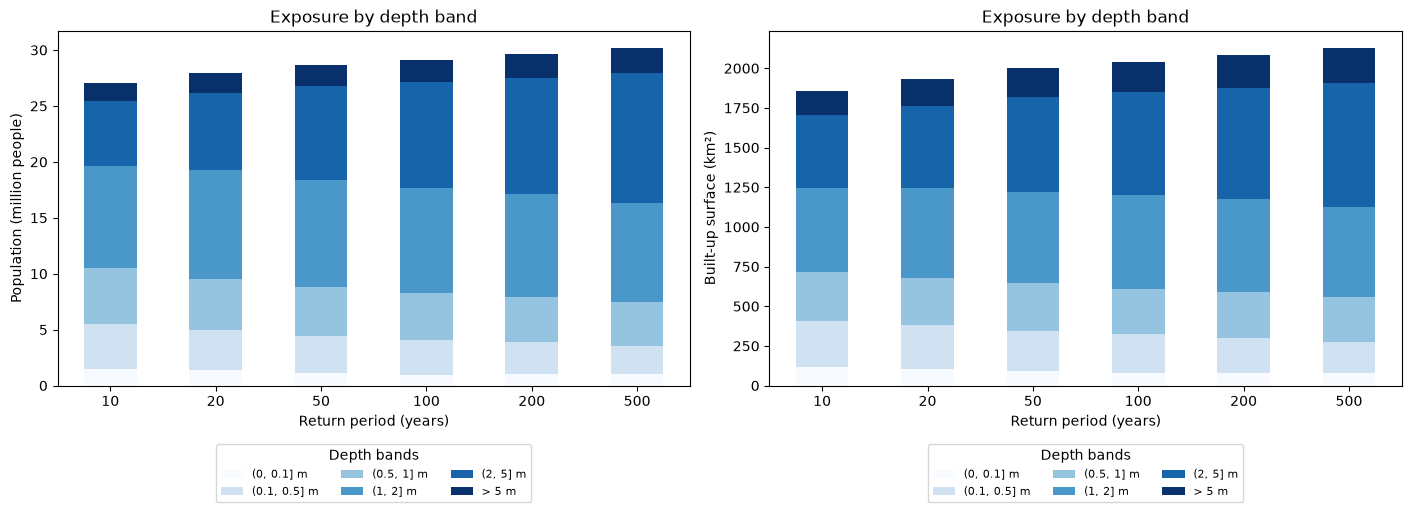

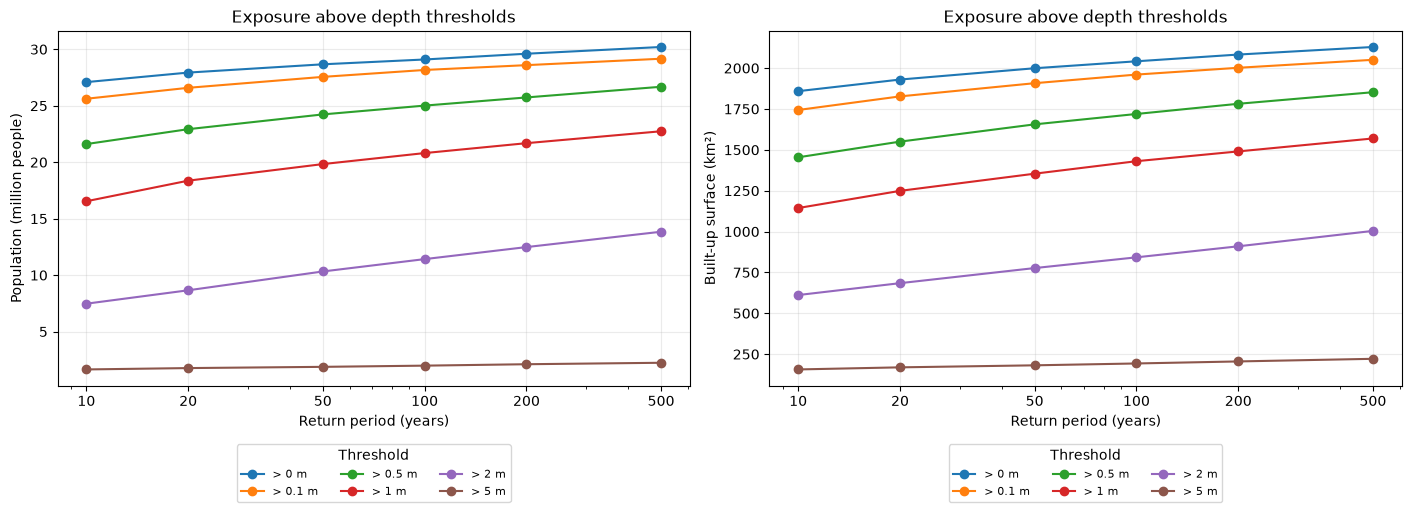

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, quantity, divisor, ylabel in [
    (axes[0], "population_people", 1e6, "Population (million people)"),
    (axes[1], "built_up_m2", 1e6, "Built-up surface (km²)"),
]:
    table = bands.pivot(index="return_period_years", columns="depth_band", values=quantity)
    table = table.reindex(index=list(flood_paths), columns=band_labels)
    (table / divisor).plot.bar(stacked=True, ax=ax, colormap="Blues", rot=0)
    ax.set(xlabel="Return period (years)", ylabel=ylabel, title="Exposure by depth band")
    ax.legend(title="Depth bands", fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, quantity, divisor, ylabel in [
    (axes[0], "population_people", 1e6, "Population (million people)"),
    (axes[1], "built_up_m2", 1e6, "Built-up surface (km²)"),
]:
    table = thresholds.pivot(
        index="return_period_years", columns="depth_threshold_m_exclusive", values=quantity
    ).sort_index()
    for threshold in depth_breaks_m:
        ax.plot(table.index, table[threshold] / divisor, marker="o", label=f"> {threshold:g} m")
    ax.set(xlabel="Return period (years)", ylabel=ylabel, title="Exposure above depth thresholds")
    ax.set_xscale("log")
    ax.set_xticks(list(flood_paths), labels=[str(rp) for rp in flood_paths])
    ax.grid(alpha=0.25)
    ax.legend(title="Threshold", fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.show()

## Save results

CSV files are plain-text tables that can be read with pandas or a spreadsheet. These cells write into `tha-demos/results/flood_exposure_2025`; rerunning replaces files with the same names. Computed values retain precision, but should be rounded for presentation.

The metadata and settings exports record the input files, grid information, year, depth rules and alignment method alongside the results. The open-ended final band has an infinite upper limit, represented as `inf` in the CSV.

In [12]:
import json

OUTPUT_DIR = DEMO_DIR / "results/flood_exposure_2025"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, table in {
    "exposure_by_depth_band": bands,
    "exposure_above_depth_threshold": thresholds,
    "hazard_coverage": coverage,
    "national_exposure_totals": national_totals,
    "raster_metadata": metadata,
}.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
settings = {
    "exposure_year": 2025,
    "population_file": str(POP_PATH), "built_up_file": str(BUILT_PATH),
    "boundary_file": str(BOUNDARY_PATH),
    "flood_files": {str(rp): str(path) for rp, path in flood_paths.items()},
    "depth_breaks_m": depth_breaks_m,
    "band_rule": "lower < depth <= upper; final band depth > 5 m",
    "threshold_rule": "depth > threshold",
    "boundary_rule": "cell centre inside ADM0; all_touched=False",
    "alignment": "nearest flood depth onto each original exposure grid",
    "hazard_nodata": "excluded from depth summaries; reported in coverage table",
    "units": {"population_people": "people", "built_up_m2": "square metres"},
}
(OUTPUT_DIR / "analysis_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print("Results saved to", OUTPUT_DIR)

Results saved to /home/mert2014/projects/snail-datapkg-demos/tha-demos/results/flood_exposure_2025


## Data and library references

The starter kit's `datapackage.json` contains source and licence information.
- `jrc_ghsl.csv` identifies the GHSL R2023A 2025 layers
- `jrc_floods.csv` lists the six available river flooding return period hazard maps

- European Commission, JRC: [GHS-POP R2023A](https://human-settlement.emergency.copernicus.eu/ghs_pop2023.php), population grid.
- European Commission, JRC: [GHS-BUILT-S R2023A](https://human-settlement.emergency.copernicus.eu/ghs_buS2023.php), built-up surface in square metres.
- European Commission, JRC: [Global river flood hazard maps](https://data.jrc.ec.europa.eu/dataset/jrc-floods-floodmapgl_rp50y-tif), modelled water depths in metres. The catalogue describes coverage limitations and notes that the dataset is not an official flood hazard map.

The main Python packages we have used are:
- [NumPy](https://numpy.org/doc/stable/) for array maths
- [pandas](https://pandas.pydata.org/docs/) for tabular data
- [Matplotlib](https://matplotlib.org/stable/) for plotting
- [Rasterio](https://rasterio.readthedocs.io/) for raster geographic data
- [GeoPandas](https://geopandas.org/en/stable/) for vector geographic data